# PC1 – PCA of the superhero data

**Goal:** apply a Principal Component Analysis (PCA) to a small data set of Marvel superheroes and interpret the result.

We follow the "analysis recipe" from the lecture (VO03, slide 14):
1. **Data understanding** – meaning and size of the variables, EDA (are there linear dependencies?)
2. **Normalize?** – decide based on units / scales of the variables
3. **Compute the PCA** and look at the principal components
4. **Choose the number of dimensions p̃** with the (cumulative) explained variance
5. **Interpretation** – coefficients of the first PCs and the biplot

**Short reminder – what PCA does:** PCA rotates the coordinate system so that the first new axis (PC1) points in the direction of the
largest spread of the data, PC2 in the direction of the second largest spread (orthogonal to PC1), and so on. Every PC is a
*linear combination* of the original variables: `PC1 = a1·x1 + a2·x2 + … + ap·xp`. The coefficients `a` are called **loadings**.

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.precision", 3)

## (a) Data understanding

The csv file has **no header**. The names of the heroes (rows) and of the variables (columns) are given in `superherosReadme.txt`,
so we read them from there. Missing values are written as `NaN` in the file – pandas recognises this automatically.

In [2]:
columns = ["Height", "Intelligence", "Strength", "Speed", "Agility", "FightingSkills", "Health"]

# hero names = all quoted strings in the readme (in the same order as the rows of the csv)
readme = open("../superherosReadme.txt", encoding="utf-8").read()
heroes = re.findall(r'"([^"]+)"', readme)

df = pd.read_csv("../superheros.csv", header=None, names=columns)
df.index = heroes
print("shape:", df.shape)
df.head(10)

shape: (58, 7)


,Height,Intelligence,Strength,Speed,Agility,FightingSkills,Health
Black Panther,180.0,7.0,29,7.0,17,79.0,140.0
Black Widow,168.0,4.0,26,4.0,14,81.0,100.0
Captain America,186.0,4.0,29,6.0,16,86.0,140.0
Electra,173.0,4.0,15,6.0,16,80.0,100.0
Hawkeye,188.0,3.0,26,4.0,16,80.0,80.0
Iceman,170.0,3.0,28,4.0,12,70.0,90.0
Invisible Woman,165.0,3.0,23,2.0,12,70.0,76.0
Iron Man,183.0,6.0,48,2.0,12,85.0,175.0
Mr Fantastic,183.0,9.0,23,2.0,22,65.0,52.0
Professor X,180.0,7.0,24,1.0,12,64.0,32.0


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Height,57.0,181.982,11.778,158.0,175.0,180.0,186.00,222.0
Intelligence,54.0,4.519,1.679,2.0,3.0,4.0,5.00,9.0
Strength,58.0,33.690,8.740,15.0,27.0,32.0,37.75,50.0
Speed,57.0,6.684,3.938,1.0,4.0,6.0,9.00,20.0
Agility,58.0,17.241,4.207,10.0,14.0,17.0,20.00,30.0
FightingSkills,57.0,76.088,9.076,55.0,70.0,75.0,85.00,95.0
Health,54.0,149.056,72.816,32.0,101.5,140.0,167.50,375.0


In [4]:
print("missing values per column:")
print(df.isna().sum())
print("\nrows with at least one missing value:", df.isna().any(axis=1).sum())
df[df.isna().any(axis=1)]

missing values per column:
Height            1
Intelligence      4
Strength          0
Speed             1
Agility           0
FightingSkills    1
Health            4
dtype: int64

rows with at least one missing value: 10


,Height,Intelligence,Strength,Speed,Agility,FightingSkills,Health
Apocalyse,NaN,8.0,50,16.0,22,80.0,295.0
Dr Doom,180.0,8.0,48,4.0,13,NaN,140.0
Agent X,180.0,4.0,37,7.0,20,94.0,NaN
Bishop,195.0,NaN,29,NaN,16,78.0,120.0
Cyclops,183.0,NaN,30,6.0,16,80.0,90.0
Jean Grey,165.0,5.0,26,4.0,16,75.0,NaN
Rogue,170.0,4.0,40,11.0,23,72.0,NaN
Warbird,177.0,NaN,36,14.0,27,75.0,180.0
Soldier X,200.0,4.0,35,6.0,19,93.0,NaN
Toad,170.0,NaN,35,9.0,20,82.0,140.0


**What do we have?**

- **Rows:** 58 Marvel characters (heroes and villains, e.g. Iron Man, Hulk, Magneto, Wolverine).
- **Columns:** 7 numeric attributes: `Height` (in cm, 158 – 222), `Intelligence` (small score 2 – 9),
  `Strength` (15 – 50), `Speed` (1 – 20), `Agility` (10 – 30), `FightingSkills` (55 – 95) and `Health` (32 – 375).
- All entries are numbers (integers), but they have **very different units and ranges**: height is in cm,
  the others are scores on different, unknown scales. The standard deviation of `Health` (≈ 73) is about 40 times larger than
  that of `Intelligence` (≈ 1.7).
- There are **11 missing values** in 10 rows.

**Missing values:** PCA cannot handle `NaN`. Deleting 10 of 58 rows would throw away 17 % of the data, so we **impute with the
median** of each column (simple and robust against outliers, see Lab 02). With only 11 of 406 cells affected, this hardly
changes the result.

In [5]:
df_imp = df.fillna(df.median())
print("missing values left:", df_imp.isna().sum().sum())

missing values left: 0


### EDA: are there linear dependencies?

PCA only makes sense if the variables are (linearly) correlated – otherwise there is no redundancy to remove.
We look at the correlation matrix and a scatter matrix.

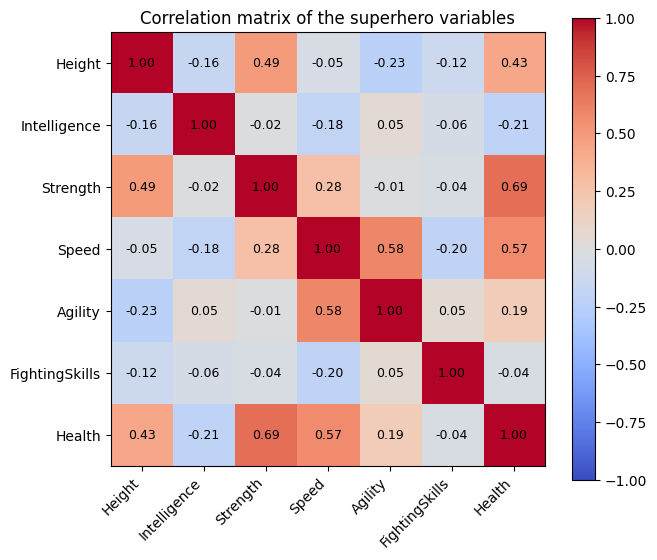

In [6]:
corr = df_imp.corr()
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(columns)), columns, rotation=45, ha="right")
ax.set_yticks(range(len(columns)), columns)
for i in range(len(columns)):
    for j in range(len(columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im)
ax.set_title("Correlation matrix of the superhero variables")
plt.show()

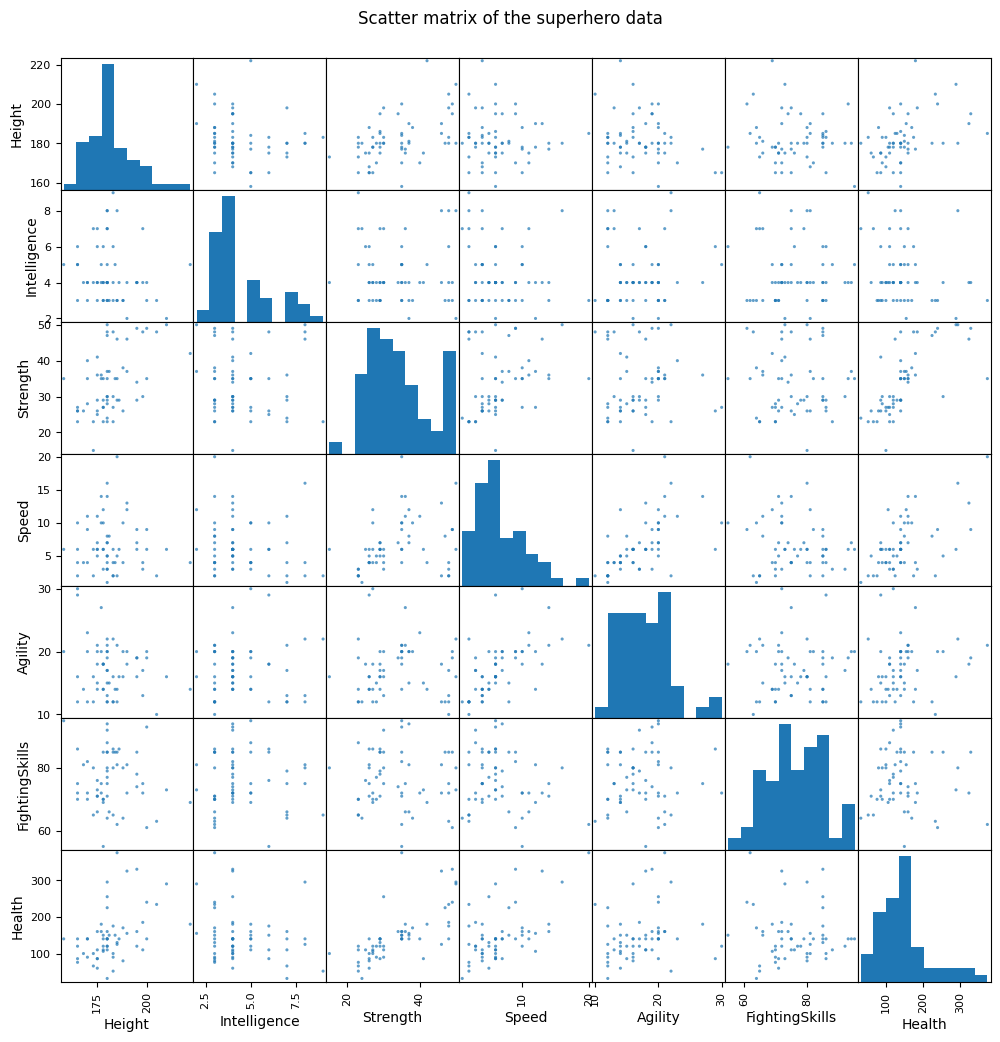

In [7]:
pd.plotting.scatter_matrix(df_imp, figsize=(12, 12), diagonal="hist", alpha=0.7, s=20)
plt.suptitle("Scatter matrix of the superhero data", y=0.92)
plt.show()

**Observations from the EDA:**
- There are some clear positive correlations: `Strength` – `Health` (0.70), `Speed` – `Health` / `Speed` – `Agility` (≈ 0.58),
  `Height` – `Strength` (0.51), `Height` – `Health` (0.47).
- `Intelligence` and `FightingSkills` are almost uncorrelated with everything else.
- So PCA makes sense (there is some linear redundancy), but we should **not expect** that 1–2 components are enough –
  the correlations are only moderate.

### Should we normalize?

**Yes.** The variables have different units (cm vs. scores) and very different scales. Without normalization, PCA maximises
variance in absolute units, and `Health` (variance ≈ 5300) would dominate everything. We check this quickly:

In [8]:
pca_raw = PCA().fit(df_imp)
print("explained variance ratio WITHOUT standardization:", pca_raw.explained_variance_ratio_.round(3))
print("PC1 loadings without standardization:")
print(pd.Series(pca_raw.components_[0], index=columns).round(3))

explained variance ratio WITHOUT standardization: [0.95  0.023 0.015 0.007 0.003 0.001 0.   ]
PC1 loadings without standardization:
Height            0.072
Intelligence     -0.005
Strength          0.086
Speed             0.031
Agility           0.011
FightingSkills   -0.006
Health            0.993
dtype: float64


➡ Without standardization PC1 explains 95 % of the variance – but PC1 is just `Health` (loading 0.99). This is an artifact of the
scale, not a real structure. Therefore we **standardize** every variable to mean 0 and standard deviation 1 (z-score,
`StandardScaler`). PCA on standardized data is the same as PCA on the **correlation matrix** (as described in the lecture).

## (b) Calculate the PCA and give out the principal components

In [9]:
scaler = StandardScaler()
X = scaler.fit_transform(df_imp)          # standardized data, 58 x 7

pca = PCA()                               # keep all 7 components first
scores = pca.fit_transform(X)             # coordinates of the heroes in the new system (58 x 7)

pc_names = [f"PC{i+1}" for i in range(len(columns))]
loadings = pd.DataFrame(pca.components_.T, index=columns, columns=pc_names)
print("All principal components (columns = PCs, rows = coefficients of the original variables):")
loadings

All principal components (columns = PCs, rows = coefficients of the original variables):


,PC1,PC2,PC3,PC4,PC5,PC6,PC7
Height,0.339,-0.528,-0.033,-0.016,0.720,-0.203,-0.213
Intelligence,-0.179,0.055,-0.631,0.698,0.020,-0.278,-0.044
Strength,0.504,-0.256,-0.072,0.336,-0.306,0.646,-0.227
Speed,0.448,0.480,-0.054,-0.155,-0.152,-0.373,-0.617
Agility,0.195,0.648,0.014,0.160,0.564,0.374,0.239
FightingSkills,-0.112,0.024,0.766,0.582,0.017,-0.174,-0.175
Health,0.590,-0.035,0.071,0.109,-0.214,-0.393,0.658


Each **column** of this table is one principal component, i.e. one new axis. The numbers are the coefficients (loadings)
of the standardized original variables. Every column has length 1 and all columns are orthogonal to each other
(it is a rotation matrix). We check this:

In [10]:
W = pca.components_
print("W · W^T = identity?", np.allclose(W @ W.T, np.eye(len(columns))))
print("eigenvalues (variance of each PC):", pca.explained_variance_.round(3))

W · W^T = identity? True
eigenvalues (variance of each PC): [2.44  1.646 1.089 0.981 0.494 0.282 0.19 ]


### Coefficients of the first principal component

Intelligence     -0.179
FightingSkills   -0.112
Agility           0.195
Height            0.339
Speed             0.448
Strength          0.504
Health            0.590
Name: PC1, dtype: float64


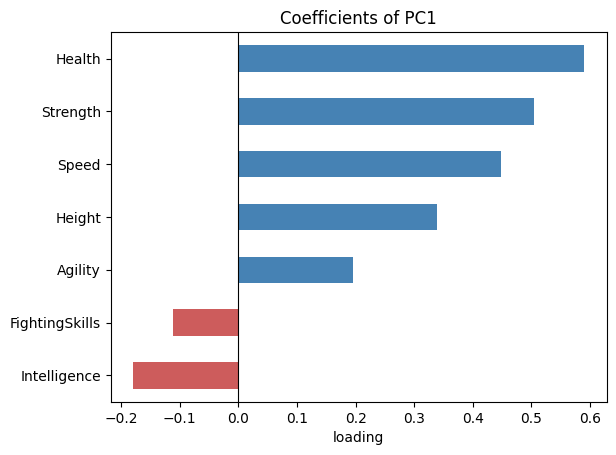

In [11]:
pc1 = loadings["PC1"].sort_values()
print(pc1.round(3))

pc1.plot(kind="barh", color=["indianred" if v < 0 else "steelblue" for v in pc1])
plt.axvline(0, color="k", lw=0.8)
plt.title("Coefficients of PC1")
plt.xlabel("loading")
plt.show()

So the first principal component is

`PC1 ≈ 0.59·Health + 0.50·Strength + 0.45·Speed + 0.34·Height + 0.19·Agility − 0.11·FightingSkills − 0.18·Intelligence`

(all variables standardized). `Health`, `Strength`, `Speed` and `Height` have large positive weights, `Intelligence` and
`FightingSkills` have small weights. We interpret this in part (d). We can also check that the score of one hero is exactly this
linear combination:

In [12]:
hero = "Hulk"
i = heroes.index(hero)
print(f"{hero}: PC1 score from PCA      = {scores[i, 0]:.3f}")
print(f"{hero}: manual linear combination = {X[i] @ loadings['PC1'].values:.3f}")

Hulk: PC1 score from PCA      = 3.149
Hulk: manual linear combination = 3.149


## (c) Assess the number of needed dimensions

We use the **explained variance ratio**: the share of the total variance that each PC captures.
Rule of thumb from the lecture: keep enough PCs to preserve **90 – 95 %** of the cumulative variance.
A second common rule for standardized data is the **Kaiser criterion**: keep PCs with eigenvalue > 1 (they explain more than one
original variable).

In [13]:
def scree_plot(pca, max_pc=None, title=""):
    ratio = pca.explained_variance_ratio_[:max_pc]
    cum = np.cumsum(pca.explained_variance_ratio_)[:max_pc]
    x = np.arange(1, len(ratio) + 1)
    fig, ax = plt.subplots(figsize=(10, 4.5))
    ax.bar(x, ratio, color="steelblue", label="explained variance per PC")
    ax.plot(x, cum, "ko-", ms=3, label="cumulative explained variance")
    for t, c in [(0.9, "orange"), (0.95, "red")]:
        ax.axhline(t, color=c, ls="--", lw=1, label=f"{int(t*100)} %")
    ax.set_xlabel("principal component"); ax.set_ylabel("proportion of variance")
    ax.set_ylim(0, 1.05); ax.set_title(title); ax.legend(loc="center right")
    plt.show()


     eigenvalue  explained variance  cumulative
PC1       2.440               0.343       0.343
PC2       1.646               0.231       0.574
PC3       1.089               0.153       0.727
PC4       0.981               0.138       0.864
PC5       0.494               0.069       0.934
PC6       0.282               0.040       0.973
PC7       0.190               0.027       1.000


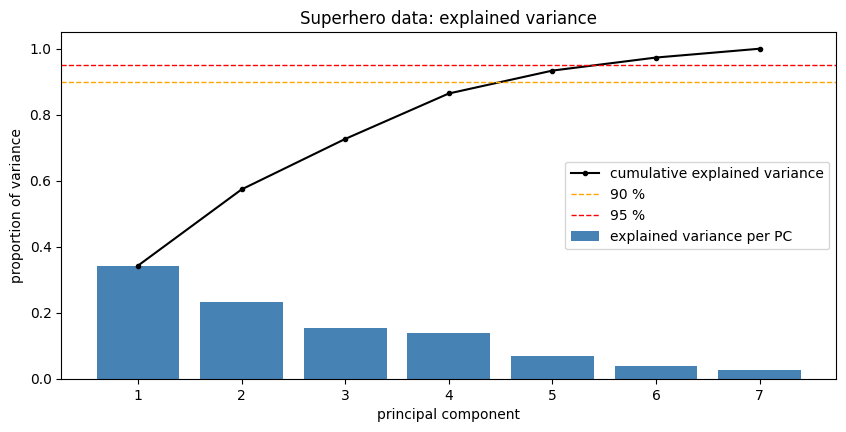

In [14]:
ev = pd.DataFrame({
    "eigenvalue": pca.explained_variance_,
    "explained variance": pca.explained_variance_ratio_,
    "cumulative": np.cumsum(pca.explained_variance_ratio_),
}, index=pc_names)
print(ev.round(3))
scree_plot(pca, title="Superhero data: explained variance")

**Assessment:**
- PC1 explains only **34 %**, PC1 + PC2 together **57 %** of the variance.
- For **90 %** we need **5** components (93 %), 4 components give 86 %.
- Kaiser criterion (eigenvalue > 1): **3** components (PC4 with 0.98 is just below the limit).
- The curve rises slowly and has no clear "elbow". This fits the EDA: the variables are only moderately correlated,
  and `Intelligence` and `FightingSkills` are almost independent of the rest – each of them needs "its own" dimension
  (PC3 and PC4 are mostly these two variables, see the loadings table).

➡ **Conclusion:** the 7 dimensions can only be reduced to about **4 – 5** without losing much information. A 2-D plot
(57 %) is useful for a first look, but it hides a large part of the information.

## (d) Interpretation: biplot with labeled variable names

A **biplot** combines two things in one plot:
- **points** = the heroes, at their scores on PC1 and PC2,
- **arrows** = the original variables; the arrow of variable *k* points to (loading on PC1, loading on PC2).

How to read it:
- Arrows that point in the **same direction** belong to positively correlated variables.
- A **long** arrow means that the variable is well represented in this 2-D plane; a short arrow means it mostly lives in other PCs.
- A hero that lies **in the direction of an arrow** has a high value of that variable.

In [15]:
def biplot(scores, loadings, var_names, labels=None, colors=None, pcs=(0, 1), ax=None, arrow_scale=None):
    """Scores as points, loadings (variable coefficients) as arrows."""
    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 8))
    i, j = pcs
    xs, ys = scores[:, i], scores[:, j]
    ax.scatter(xs, ys, c=colors if colors is not None else "lightgrey", s=25, alpha=0.8, edgecolor="k", linewidth=0.3)
    if labels is not None:
        for x, y, lab in zip(xs, ys, labels):
            ax.annotate(lab, (x, y), fontsize=7, alpha=0.7, xytext=(2, 2), textcoords="offset points")
    # scale arrows so they are visible next to the points
    if arrow_scale is None:
        arrow_scale = 0.9 * min(np.abs(xs).max(), np.abs(ys).max()) / np.abs(loadings[:, [i, j]]).max()
    for k, name in enumerate(var_names):
        dx, dy = loadings[k, i] * arrow_scale, loadings[k, j] * arrow_scale
        ax.arrow(0, 0, dx, dy, color="red", width=0.01 * arrow_scale * np.abs(loadings).max(),
                 head_width=0.05 * arrow_scale * np.abs(loadings).max(), length_includes_head=True, alpha=0.8)
        ax.text(dx * 1.12, dy * 1.12, name, color="darkred", fontsize=10, ha="center", va="center", fontweight="bold")
    ax.axhline(0, color="grey", lw=0.5); ax.axvline(0, color="grey", lw=0.5)
    ax.set_xlabel(f"PC{i+1}"); ax.set_ylabel(f"PC{j+1}")
    return ax


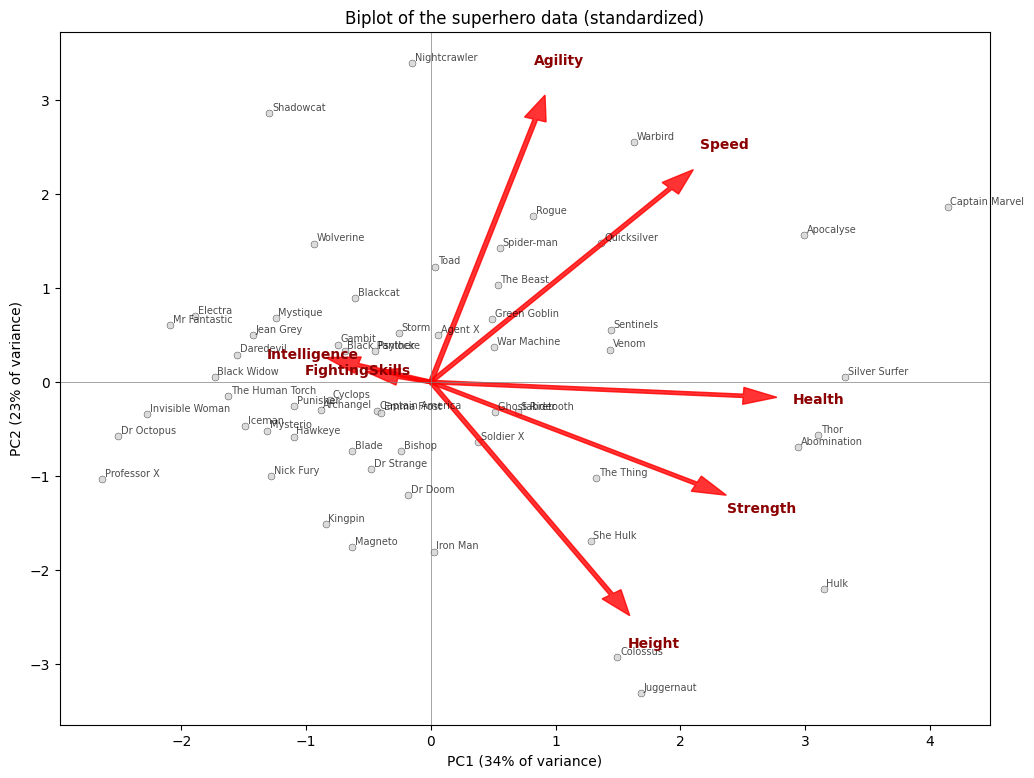

In [16]:
fig, ax = plt.subplots(figsize=(12, 9))
biplot(scores, pca.components_.T, columns, labels=heroes, ax=ax)
r = pca.explained_variance_ratio_
ax.set_xlabel(f"PC1 ({r[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({r[1]:.0%} of variance)")
ax.set_title("Biplot of the superhero data (standardized)")
plt.show()

To check our reading of the plot, we look at the heroes with the most extreme scores on PC1 and PC2:

In [17]:
s = pd.DataFrame(scores[:, :2], index=heroes, columns=["PC1", "PC2"])
show = columns
print("Highest PC1:"); print(df_imp.loc[s["PC1"].nlargest(5).index, show], "\n")
print("Lowest PC1:");  print(df_imp.loc[s["PC1"].nsmallest(5).index, show], "\n")
print("Highest PC2:"); print(df_imp.loc[s["PC2"].nlargest(5).index, show], "\n")
print("Lowest PC2:");  print(df_imp.loc[s["PC2"].nsmallest(5).index, show])

Highest PC1:
                Height  Intelligence  Strength  Speed  Agility  \
Captain Marvel   185.0           3.0        35   20.0       21   
Silver Surfer    190.0           4.0        46   13.0       18   
Hulk             210.0           2.0        50    6.0       16   
Thor             195.0           4.0        49    9.0       19   
Apocalyse        180.0           8.0        50   16.0       22   

                FightingSkills  Health  
Captain Marvel            62.0   375.0  
Silver Surfer             72.0   325.0  
Hulk                      73.0   290.0  
Thor                      85.0   330.0  
Apocalyse                 80.0   295.0   

Lowest PC1:
                 Height  Intelligence  Strength  Speed  Agility  \
Professor X       180.0           7.0        24    1.0       12   
Dr Octopus        173.0           7.0        23    2.0       12   
Invisible Woman   165.0           3.0        23    2.0       12   
Mr Fantastic      183.0           9.0        23    2.0       2

### What do the first two PCs mean?

**PC1 – "overall physical power" (34 %)**
- All the physical variables `Health`, `Strength`, `Speed`, `Height` (and a bit `Agility`) point to the right.
- High PC1 = big, strong, fast characters with a lot of health, e.g. *Captain Marvel, Silver Surfer, Thor, Hulk, Apocalypse*.
- Low PC1 = "normal" humans with small physical values, e.g. *Professor X, Dr Octopus, Invisible Woman, Mr Fantastic*.
- `Intelligence` and `FightingSkills` have only very short arrows → they are almost not represented in this plane.

**PC2 – "nimble/fast vs. big/heavy" (23 %)**
- `Agility` and `Speed` point upwards, `Height` (and partly `Strength`) point downwards.
- High PC2 = agile, fast and rather small characters, e.g. *Nightcrawler, Shadowcat, Warbird, Rogue* (also Spider-man, Quicksilver).
- Low PC2 = tall, heavy characters with low agility, e.g. *Juggernaut, Colossus, Hulk, Iron Man, Magneto*.

So PC1 says *how powerful* a character is, and PC2 says *what kind of* power it has (agility/speed vs. size/strength).

**Other observations:**
- The arrows of `Strength`, `Health` and `Height` lie close together → these are positively correlated (as in the correlation matrix).
- `Agility` is almost orthogonal to `Strength` → uncorrelated (r ≈ 0).
- Because PC1 + PC2 only explain 57 %, distances between heroes in this plot are only approximately right. Heroes that are
  close in the plot may still differ in intelligence or fighting skills (those are in PC3 and PC4).

## Summary

| Question | Answer |
|---|---|
| (a) Data | 58 Marvel characters × 7 numeric attributes, different units/scales, 11 missing values (imputed with the median). **Standardize: yes** – otherwise `Health` dominates PC1 (95 %). |
| (b) PCA | 7 PCs. PC1 ≈ 0.59·Health + 0.50·Strength + 0.45·Speed + 0.34·Height + 0.19·Agility − 0.11·FightingSkills − 0.18·Intelligence |
| (c) Dimensions | PC1 34 %, PC1+PC2 57 %. 90 % needs **5** PCs, Kaiser criterion gives 3. No strong reduction is possible, because the variables are only moderately correlated. |
| (d) Biplot | PC1 = overall physical power (Captain Marvel, Thor, Hulk vs. Professor X), PC2 = agile/fast vs. tall/heavy (Nightcrawler, Shadowcat vs. Juggernaut, Colossus). |